In [1]:
#Importing needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
from sklearn.decomposition import PCA

In [2]:
#Reading in the original dataset
user_games = pd.read_parquet("user_games.parquet")

print(user_games.shape)
print(user_games.columns.to_list())

user_games.head()

(11285290, 9)
['steamid', 'appid', 'game_count', 'game_name', 'playtime_forever', 'img_icon_url', 'has_community_visible_stats', 'has_leaderboards', 'content_descriptorids']


,steamid,appid,game_count,game_name,playtime_forever,img_icon_url,has_community_visible_stats,has_leaderboards,content_descriptorids
0,76561197960293516,10,13024,Counter-Strike,599979,6b0312cda02f5f777efa2f3318c307ff9acafbb5,False,False,"[2, 5]"
1,76561197960293516,20,13024,Team Fortress Classic,0,38ea7ebe3c1abbbbf4eabdbef174c41a972102b9,False,False,"[2, 5]"
2,76561197960293516,30,13024,Day of Defeat,0,aadc0ce51ff6ba2042d633f8ec033b0de62091d0,False,False,"[2, 5]"
3,76561197960293516,40,13024,Deathmatch Classic,0,c525f76c8bc7353db4fd74b128c4ae2028426c2a,False,False,[]
4,76561197960293516,50,13024,Half-Life: Opposing Force,0,04e81206c10e12416908c72c5f22aad411b3aeef,False,False,"[2, 5]"


In [10]:
#Cleaning data
user_games = user_games[["steamid", "game_name"]].copy()

user_games = user_games.rename(columns = {
    "steamid": "user_id",
    "game_name": "game"                               
})

user_games = user_games.dropna()
user_games = user_games.drop_duplicates()

print("Unique users:", user_games["user_id"].nunique())
print("Unique games:", user_games["game"].nunique())
print("User-game relationships:", len(user_games))

Unique users: 786
Unique games: 49664
User-game relationships: 11269997


In [11]:
#Selecting games for clustering
top_games = (
    user_games["game"].value_counts().head(500).index
)

cluster_data = user_games[
    user_games["game"].isin(top_games)
].copy()

print("Games selected:", cluster_data["game"].nunique())
print("Records selected:", len(cluster_data))

Games selected: 500
Records selected: 387446


In [12]:
#Creating user-game matrix
user_codes, unique_users = pd.factorize(
    cluster_data["user_id"]
)

game_codes, unique_games = pd.factorize(
    cluster_data["game"]
)

A = csr_matrix(
    (
        np.ones(len(cluster_data), dtype=np.int32),
        (user_codes, game_codes)
    ),
    shape=(len(unique_users), len(unique_games))
)

print("Matrix shape:", A.shape)

Matrix shape: (786, 500)


In [13]:
#Calculating Jaccard distance
shared = (A.T @ A).toarray()

game_counts = np.asarray(A.sum(axis=0)).ravel()

union = (
    game_counts[:, None]
    + game_counts[None, :]
    - shared
)

jaccard = np.divide(
    shared,
    union,
    out=np.zeros_like(shared, dtype=float),
    where=union != 0
)

distance = 1 - jaccard

np.fill_diagonal(distance, 0)

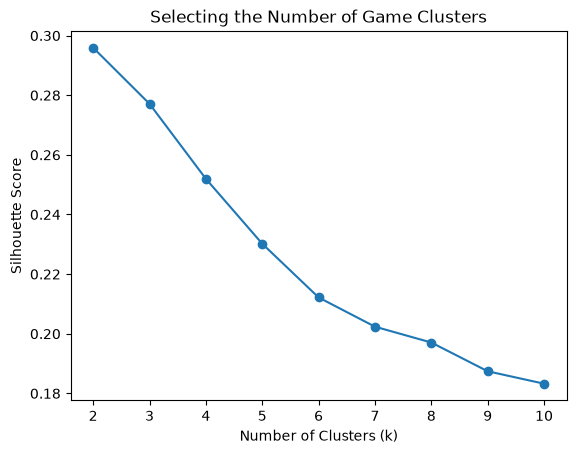

In [35]:
#Finding best k value
scores = {}

for k in range(2, 11):
    model = AgglomerativeClustering(
        n_clusters=k,
        metric="precomputed",
        linkage="average"
    )

    labels = model.fit_predict(distance)

    scores[k] = silhouette_score(
        distance,
        labels,
        metric="precomputed"
    )

plt.plot(
    list(scores.keys()),
    list(scores.values()),
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Selecting the Number of Game Clusters")
plt.show()

In [44]:
#Creating and inspecting the clusters

for k in range(2, 11):
    model = AgglomerativeClustering(
        n_clusters = k,
        metric="precomputed",
        linkage="average"
    )

    labels = model.fit_predict(distance)

    cluster_df = pd.DataFrame({
        "game": unique_games,
        "cluster": labels
    })

    for cluster_id, group in cluster_df.groupby("cluster"):
        print(f"\nCluster {cluster_id}")
        print("Size:", len(group))
        print(group["game"].head(15).to_string(index=False))

    print("\n")


Cluster 0
Size: 499
                             Half-Life
                 Half-Life: Blue Shift
                           Half-Life 2
               Half-Life 2: Deathmatch
          Half-Life Deathmatch: Source
                                Portal
                         Left 4 Dead 2
                              Portal 2
                         Killing Floor
              Two Worlds: Epic Edition
                         Shadowgrounds
       King's Bounty: Armored Princess
                          Sniper Elite
                           Psychonauts
Sid Meier's Civilization III: Complete

Cluster 1
Size: 1
Ken Follett's The Pillars of the Earth



Cluster 0
Size: 497
                             Half-Life
                 Half-Life: Blue Shift
                           Half-Life 2
               Half-Life 2: Deathmatch
          Half-Life Deathmatch: Source
                                Portal
                         Left 4 Dead 2
                              Portal 2
 

In [ ]:
#Checking size of each cluster
cluster_df["cluster"].value_counts().sort_index()

cluster
0    494
1      1
2      2
3      1
4      1
5      1
Name: count, dtype: int64

When using Jaccard distance, cannot get meaningful cluster distribution.


In [ ]:

#Trying k means with normalized game freatures
game_matrix = A.T

svd = TruncatedSVD(
    n_components=50,
    random_state=42
)

game_features = svd.fit_transform(game_matrix)

game_features = normalize(game_features)

In [ ]:
#Testing different values of k
scores = {}
inertias = {}

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(game_features)

    scores[k] = silhouette_score(game_features, labels)
    inertias[k] = model.inertia_

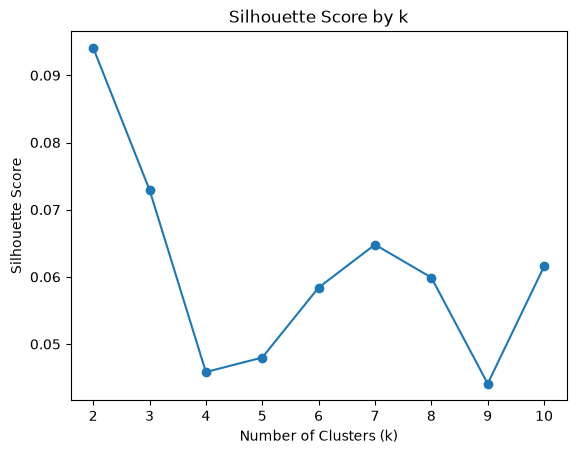

In [62]:
#Plotting both metrics

plt.plot(list(scores.keys()), list(scores.values()), marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by k")
plt.show()

In [58]:
#
for k in [2, 3, 7]:
    model = KMeans(
        n_clusters = k,
        random_state = 42,
        n_init = 10
    )

    labels = model.fit_predict(game_features)

    temp_df = pd.DataFrame({
        "game": unique_games,
        "cluster": labels
    })

    print(f"\n========== k = {k} ==========")
    print("Cluster sizes:")
    print(temp_df["cluster"].value_counts().sort_index())

    for cluster_id, group in temp_df.groupby("cluster"):
        print(f"\nCluster {cluster_id}:")
        print(group["game"].head(10).to_string(index=False))


========== k = 2 ==========
Cluster sizes:
cluster
0    200
1    300
Name: count, dtype: int64

Cluster 0:
                                     Shadowgrounds
                                          X-Blades
                                       NecroVisioN
                                    Death to Spies
                                           Ceville
                                      Elven Legacy
                                    Zombie Shooter
                                The Great Art Race
Broken Sword 2 - the Smoking Mirror: Remastered...
                                         Toki Tori

Cluster 1:
                   Half-Life
       Half-Life: Blue Shift
                 Half-Life 2
     Half-Life 2: Deathmatch
Half-Life Deathmatch: Source
                      Portal
               Left 4 Dead 2
                    Portal 2
               Killing Floor
    Two Worlds: Epic Edition

========== k = 3 ==========
Cluster sizes:
cluster
0    279
1    133
2     88
N

From the previous cell, I decided to go with k value of 7.

In [61]:
k = 7

kmeans = KMeans(
    n_clusters = k,
    random_state = 42,
    n_init = 10
)

labels = kmeans.fit_predict(game_features)

cluster_df = pd.DataFrame({
    "game": unique_games,
    "cluster": labels
})

print(cluster_df["cluster"].value_counts().sort_index())

cluster
0     49
1      6
2    100
3     94
4     63
5     11
6    177
Name: count, dtype: int64


In [60]:

#Identifying representative games
center_distances = pairwise_distances(
    game_features,
    kmeans.cluster_centers_
)

cluster_df["distance_to_center"] = center_distances[
    np.arange(len(labels)),
    labels
]

for cluster_id in range(k):
    print(f"\nCluster {cluster_id}")

    display(
        cluster_df[
            cluster_df["cluster"] == cluster_id
        ]
        .nsmallest(10, "distance_to_center")
        [["game", "distance_to_center"]]
    )


Cluster 0


,game,distance_to_center
55,Sniper: Ghost Warrior,0.048832
56,Sniper Ghost Warrior 2,0.051831
112,Call of Juarez Gunslinger,0.053676
79,Amnesia: The Dark Descent,0.055836
282,Lara Croft and the Temple of Osiris,0.057037
54,SEGA Mega Drive & Genesis Classics,0.062394
168,Amnesia: A Machine for Pigs,0.064356
158,Shadowrun Returns,0.064709
165,System Shock® 2 (1999),0.066010
394,Rise of the Tomb Raider,0.066200



Cluster 1


,game,distance_to_center
484,Leisure Suit Larry 2 - Looking For Love (In Se...,0.019573
485,Leisure Suit Larry 3 - Passionate Patti in Pur...,0.019573
489,Leisure Suit Larry 6 - Shape Up Or Slip Out,0.019573
487,Leisure Suit Larry 7 - Love for Sail,0.025277
486,Leisure Suit Larry 5 - Passionate Patti Does a...,0.027572
488,Leisure Suit Larry - Magna Cum Laude Uncut and...,0.053844



Cluster 2


...

,game,distance_to_center
258,This War of Mine,0.041238
29,BioShock Infinite,0.042324
411,BioShock Remastered,0.048460
205,Viscera Cleanup Detail: Shadow Warrior,0.048575
445,Darksiders Warmastered Edition,0.048657
494,LIMBO,0.049419
23,BioShock,0.049455
385,Hue,0.050377
37,Red Faction: Guerrilla Steam Edition,0.054160
480,Red Faction Guerrilla Re-Mars-tered,0.054160



Cluster 5


,game,distance_to_center
269,9 Clues: The Secret of Serpent Creek,0.044856
265,Dark Arcana: The Carnival,0.045085
270,Left in the Dark: No One on Board,0.050222
266,Enigmatis: The Ghosts of Maple Creek,0.054675
268,Grim Legends: The Forsaken Bride,0.058754
380,9 Clues 2: The Ward,0.065422
336,Demon Hunter: Chronicles from Beyond,0.068838
264,Abyss: The Wraiths of Eden,0.069495
254,Grim Legends 2: Song of the Dark Swan,0.075153
267,Clockwork Tales: Of Glass and Ink,0.075706



Cluster 6


,game,distance_to_center
5,Portal,0.019974
462,Manual Samuel - Last Tuesday Edition,0.021562
399,DISTRAINT: Deluxe Edition,0.021608
491,Gothic Playable Teaser,0.026403
74,Syberia 2,0.030141
125,Deponia,0.030644
193,Anomaly Korea,0.030644
390,In Between,0.031123
222,One Finger Death Punch,0.033116
226,The Red Solstice,0.035627


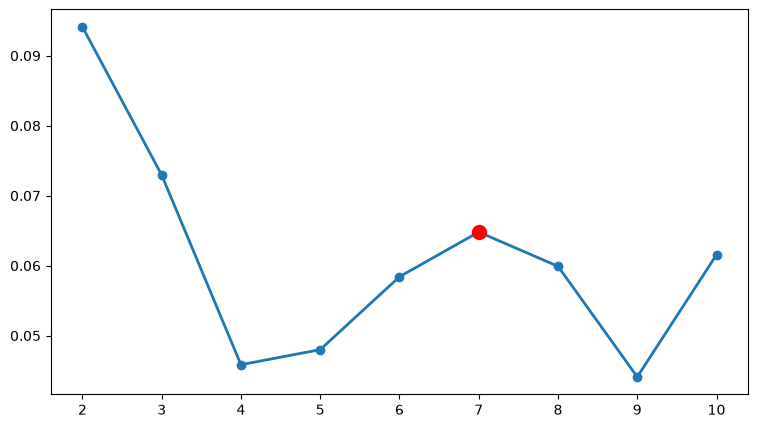

In [54]:
#Figure Creation: Silhouette Score vs. Number of Clusters
plt.figure(figsize=(9, 5))

plt.plot(
    list(scores.keys()),
    list(scores.values()),
    marker="o",
    linewidth=2
)

# Highlight the selected k=7
plt.scatter(
    7,
    scores[7],
    color="red",
    s=100,
    zorder=5,
    label="Selected k = 7"
)

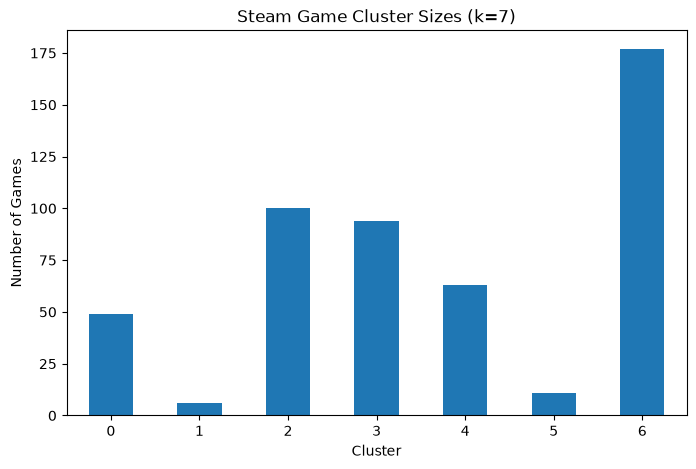

In [55]:
#Figure Creation: CLuster Distribution Chart
cluster_df["cluster"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Steam Game Cluster Sizes (k=7)")
plt.xlabel("Cluster")
plt.ylabel("Number of Games")
plt.xticks(rotation=0)
plt.show()

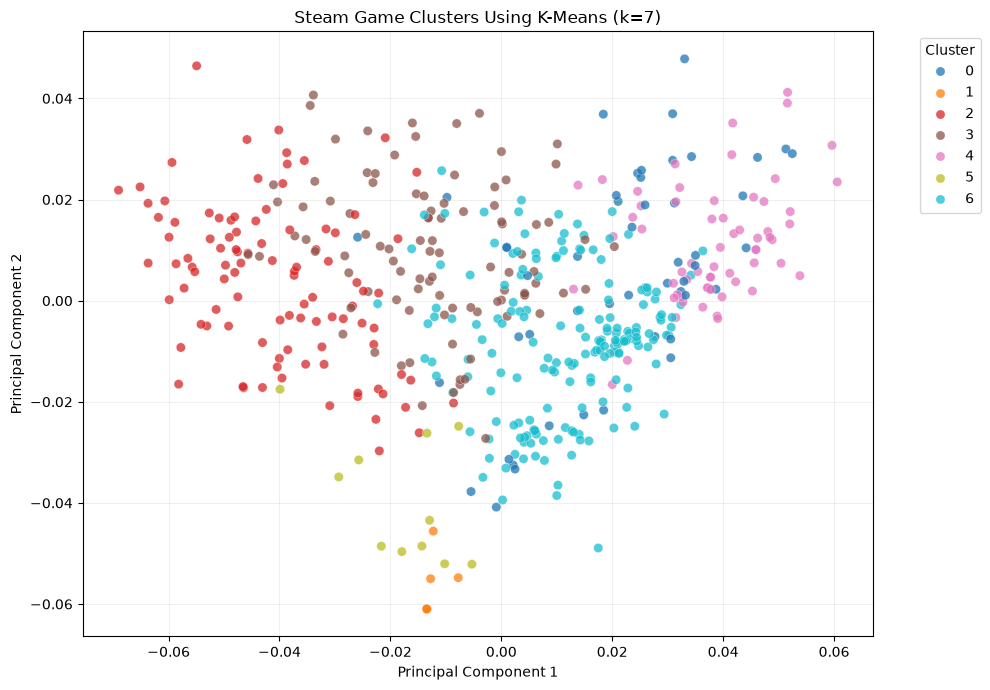

In [57]:
#Figure Creation: PCA Visualization of Game Clusters
# Reduce features to 2 dimensions
pca = PCA(
    n_components=2,
    random_state=42
)

game_2d = pca.fit_transform(game_features)

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    game_2d[:, 0],
    game_2d[:, 1],
    c=labels,
    cmap="tab10",
    s=45,
    alpha=0.75,
    edgecolors="white",
    linewidths=0.3
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Steam Game Clusters Using K-Means (k=7)")

plt.legend(
    *scatter.legend_elements(),
    title="Cluster",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "steam_game_clusters_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [53]:
#Validation
print("Number of games:", len(cluster_df))
print("Number of clusters:", cluster_df["cluster"].nunique())
print("Missing labels:", cluster_df["cluster"].isna().sum())
print("Duplicate game names:", cluster_df["game"].duplicated().sum())

print("Silhouette score:",
      silhouette_score(game_features, labels))

Number of games: 500
Number of clusters: 7
Missing labels: 0
Duplicate game names: 0
Silhouette score: 0.06480302624957247
